In [31]:
%matplotlib inline 
import numpy as np
from scipy.integrate import solve_ivp
from scipy.interpolate import interp1d
from scipy import constants
import matplotlib.pyplot as plt
import camb
MP2 = 1

def omega_r(h):
    ab = (8*constants.pi**5*constants.k**4)/(15*constants.h**3*constants.c**3)
    rhor = ab*2.7255**4/(constants.c**2)
    rhov = 3.046*(7/8)*(4/11)**(4/3)*rhor
    return((rhor+rhov)/((3*(100*h)**2/(8*constants.pi*constants.G))*(1000)**2/(10**6*constants.parsec)**2))

def aseries(tau, omega_m, h, OmL, a0, stigma, mups2):
    val = (
          (200*h*(omega_r(h))**(1/2)*(stigma)**(1/2)*tau)/(a0**2*mups2*(-1 + \
            4*stigma))**(1/2) + (2500*h**2*tau**2*(omega_m))/(a0*mups2) + \
            (15625*h**3*(stigma)**(1/2)*(-1 + 4*stigma)**(1/2)*(-2 + stigma*(5 + \
            24*stigma))*tau**3*(omega_m)**2)/(a0*mups2**(3/2)*(omega_r(h))**(1/2)*(-1 + \
            stigma)*(-3 + stigma + 8*stigma**2)) + (390625*h**4*(-1 + \
            4*stigma)*(-6 + stigma*(31 + stigma*(357 + 2*stigma*(-123 + \
            5*stigma*(-151 + \
            24*stigma)))))*tau**4*(omega_m)**3)/(2*a0*mups2**2*omega_r(h)*(-1 + \
            stigma)**2*(-3 + stigma + 8*stigma**2)*(-6 + stigma + 20*stigma**2))
    )
    return val

def cpseries(tau, omega_m, h, OmL, a0, stigma, mups2):
    val = (
       1 - (25*h*(-1 + \
            4*stigma)**(1/2)*tau*(omega_m))/(2*(mups2)**(1/2)*(omega_r(h))**(1/2)*(stigma)**(1/2)) + (1875*h**2*(-1 + \
            4*stigma)*(2 + stigma*(-2 + \
            3*stigma))*tau**2*(omega_m)**2)/(8*mups2*omega_r(h)*(-1 + stigma)*stigma*(-3 \
            + stigma + 8*stigma**2)) + (15625*h**3*(-1 + 4*stigma)**(3/2)*(-36 + \
            stigma*(72 + stigma*(175 + stigma*(-225 + 4*stigma*(-180 + stigma*(95 \
            + 48*stigma))))))*tau**3*(omega_m)**3)/(16*mups2**(3/2)*omega_r(h)**(3/2)*(-1 + stigma)**2*stigma**(3/2)*(-3 \
            + stigma + 8*stigma**2)*(-6 + stigma + 20*stigma**2))
    )
    return val

def aseriesp(tau, omega_m, h, OmL, a0, stigma, mups2):
    val = (
          (200*h*(omega_r(h))**(1/2)*(stigma)**(1/2))/(a0**2*mups2*(-1 + \
            4*stigma))**(1/2) + (5000*h**2*tau*(omega_m))/(a0*mups2) + \
            (46875*h**3*(stigma)**(1/2)*(-1 + 4*stigma)**(1/2)*(-2 + stigma*(5 + \
            24*stigma))*tau**2*(omega_m)**2)/(a0*mups2**(3/2)*(omega_r(h))**(1/2)*(-1 + \
            stigma)*(-3 + stigma + 8*stigma**2)) + (781250*h**4*(-1 + \
            4*stigma)*(-6 + stigma*(31 + stigma*(357 + 2*stigma*(-123 + \
            5*stigma*(-151 + \
            24*stigma)))))*tau**3*(omega_m)**3)/(a0*mups2**2*omega_r(h)*(-1 + \
            stigma)**2*(-3 + stigma + 8*stigma**2)*(-6 + stigma + 20*stigma**2))
    )
    return val

def cpseriesp(tau, omega_m, h, OmL, a0, stigma, mups2):
    val = (
        (-25*h*(-1 + \
        4*stigma)**(1/2)*(omega_m))/(2*(mups2)**(1/2)*(omega_r(h))**(1/2)*(stigma)**(1/2)) + (1875*h**2*(-1 + \
        4*stigma)*(2 + stigma*(-2 + \
        3*stigma))*tau*(omega_m)**2)/(4*mups2*omega_r(h)*(-1 + stigma)*stigma*(-3 + \
        stigma + 8*stigma**2)) + (46875*h**3*(-1 + 4*stigma)**(3/2)*(-36 + \
        stigma*(72 + stigma*(175 + stigma*(-225 + 4*stigma*(-180 + stigma*(95 \
        + 48*stigma))))))*tau**2*(omega_m)**3)/(16*mups2**(3/2)*omega_r(h)**(3/2)*(-1 + stigma)**2*stigma**(3/2)*(-3 \
        + stigma + 8*stigma**2)*(-6 + stigma + 20*stigma**2))
    )
    return val
    
def ddcp(a, da, cp, dcp, omega_m, h, OmL, a0, stigma, mups2):
    val = (
        (-120000*a**4*a0**4*h**2*OmL*stigma*(-cp**2 + stigma)**2*(stigma - 4*stigma**2 + cp**2*(-1 + 4*stigma**2)) + 40000*h**2*omega_r(h)*stigma*(-cp**2 + stigma)**2*(stigma - 4*stigma**2 + cp**2*(-1 + 4*stigma**2)) - a0**2*cp**2*da**2*mups2*((5 - 8*stigma)*stigma + cp**2*(-1 + 4*stigma**2))*((7 - 4*stigma)*stigma**2 + 2*cp**2*stigma*(1 + 2*(-3 + stigma)*stigma) + cp**4*(-1 + 4*stigma**2)) + a**2*a0**2*dcp**2*mups2*(stigma**3 + 4*stigma**4 - 32*stigma**5 - cp**4*stigma*(-1 + 2*stigma)*(1 + 2*stigma)*(3 + 4*(-3 + stigma)*stigma) - cp**6*(1 - 4*stigma**2)**2 + cp**2*stigma**2*(-3 + 8*stigma + 16*stigma**3)) - 2*a*a0**2*cp*da*dcp*mups2*(cp**4*stigma*(-1 + 2*stigma)*(1 + 2*stigma)*(11 + 4*(-4 + stigma)*stigma) + cp**6*(1 - 4*stigma**2)**2 + stigma**3*(-1 + 16*stigma*(-2 + 3*stigma)) + cp**2*stigma**2*(11 - 16*stigma*(1 + stigma*(-1 + 2*stigma)))))/(8*a**2*a0**2*cp*mups2*stigma*(-cp**2 + stigma)**2*(-1 + 4*stigma**2))
    )
    return val

def dda(a, da, cp, dcp, omega_m, h, OmL, a0, stigma, mups2):
    val = (a**2*a0**2*dcp**2*mups2*(3*cp**2*stigma**2 + cp**4*(1 - \
        2*stigma)**2*stigma*(-3 + 2*stigma)*(1 + 2*stigma) - stigma**3*(1 + \
        8*stigma) + cp**6*(1 - 4*stigma**2)**2) + \
        120000*a**4*a0**4*h**2*OmL*stigma*(-cp**2 + stigma)**2*(stigma + \
        cp**2*(-1 + 4*stigma**2)) - 40000*h**2*omega_r(h)*stigma*(-cp**2 + \
        stigma)**2*(stigma + cp**2*(-1 + 4*stigma**2)) + \
        2*a*a0**2*cp*da*dcp*mups2*(stigma + cp**2*(-1 + 4*stigma**2))*((7 - \
        4*stigma)*stigma**2 + 2*cp**2*stigma*(1 + 2*(-3 + stigma)*stigma) + \
        cp**4*(-1 + 4*stigma**2)) + a0**2*cp**2*da**2*mups2*(cp**4*(1 - \
        2*stigma)**2*stigma*(-7 + 2*stigma)*(1 + 2*stigma) + stigma**3*(3 + \
        32*(-1 + stigma)*stigma) + cp**6*(1 - 4*stigma**2)**2 + \
        cp**2*stigma**2*(3 - 16*(-1 + stigma)*stigma*(-1 + \
        2*stigma))))/(8*a*a0**2*cp**2*mups2*stigma*(-cp**2 + stigma)**2*(-1 \
        + 4*stigma**2))
    return val

def coupdiff(y, tau, omega_m, h, OmL, a0, stigma, mups2):
    a, cp, da, dcp = y
    dydt = [da, dcp, dda(a, da, cp, dcp, omega_m, h, OmL, a0, stigma, mups2), ddcp(a, da, cp, dcp, omega_m, h, OmL, a0, stigma, mups2)]
    return dydt

#Initial conditions
def small(omega_m, h, stigma, mups2):
    val = 1e-6*(2*(mups2)**(1/2)*(omega_r(h))**(1/2)*(stigma)**(1/2))/(25*h*(-1 + 4*stigma)**(1/2)*(omega_m))
    return val

#Stops for Solve_ivp
def hstop(h):
    def event(t, y):
        return y[2]-h*100
    event.terminal = True
    event.direction = 1
    return event

def astop(t, y):
    return y[0]-100

astop.terminal = True
astop.direction = 1

def rhopsol(omega_m, h, OmL, stigma, mups2):

    tauini = small(omega_m, h, stigma, mups2)
    print(tauini)
    
    a0 = 1
    
    y02 = [aseries(tauini, omega_m, h, OmL, 1, stigma, mups2), cpseries(tauini, omega_m, h, OmL, 1, stigma, mups2),
          aseriesp(tauini, omega_m, h, OmL, 1, stigma, mups2), cpseriesp(tauini, omega_m, h, OmL, 1, stigma, mups2)]
    
    sola0 = solve_ivp(lambda tau, y: coupdiff(y, tau, omega_m, h, OmL, 1, stigma, mups2),
                    [tauini, np.inf], y02, events = astop, rtol=1e-8, atol=1e-8)
    
    tsol = interp1d(sola0.y[0], sola0.t, bounds_error = False)
    avals = np.logspace(np.log10(sola0.y[0][0]),2,10000)
    tvals = tsol(avals)
    tvals[0] = tauini
    avals[0] = sola0.y[0][0]
    
    
    sola02 = solve_ivp(lambda tau, y: coupdiff(y, tau, omega_m, h, OmL, 1, stigma, mups2),
                    [tauini, np.inf], y02, t_eval = tvals, events = astop, rtol=1e-8, atol=1e-8)
    
    asol, varpisol, hsol, dvarpisol = sola02.y
    aend, vpend, hend, dvpend = sola02.y_events[0][0]

    if aend > asol[-1]:
        asol = np.append(asol, aend)
        hsol = np.append(hsol, hend)
        varpisol = np.append(varpisol, vpend)
        dvarpisol = np.append(dvarpisol, dvpend)

    hubble = (a0* hsol)/asol**2
    z = 1/asol-1

    return z[::-1], hubble[::-1], P_DE, rho_DE, asol

In [16]:
h = 0.7
H0 = 100*h
OmL = (1-omega_m-omega_r(h))
stigma = 1.0001
mups2 = 1.22
cpr = 1
ombh2=0.02242
omch2=0.11933
omega_m = (ombh2+omch2)/h**2

# ── 4. THEORY CURVE ───────────────────────────────────────────────────────────

z_arr, H_arr,P_DE, rho_DE, asol = rhopsol(omega_m, h, OmL, stigma, mups2)

2.327873513920562e-09


In [17]:
def H(a, omega_m, h):
    val = (h*100)*np.sqrt((omega_m*(a)**-3+omega_r(h)*(a)**-4+(1-omega_m-omega_r(h))))
    return val

In [18]:
H(1/(1+z_arr), omega_m, h)

array([5.90091777e+01, 5.90091777e+01, 5.90091778e+01, ...,
       2.58472923e+17, 2.59762146e+17, 2.61057799e+17], shape=(10000,))

In [32]:
h = 0.7
H0 = 100*h
OmL = (1-omega_m-omega_r(h))
stigma = 1.0001
mups2 = 4/3
ombh2=0.02242
omch2=0.11933
omega_m = (ombh2+omch2)/h**2

In [33]:
z_arr, H_arr,P_DE, rho_DE, asol = rhopsol(omega_m, h, OmL, stigma, mups2)
h_interp = interp1d(z_arr, H_arr / H_arr[0], kind='cubic')

2.433597956300554e-09


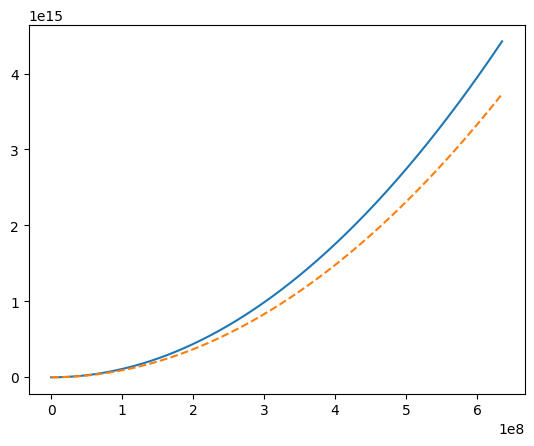

In [34]:
plt.plot(z_arr, h_interp(z_arr))
plt.plot(z_arr, H(1/(1+z_arr), omega_m, h)/(h*100), "--")

In [10]:
import numpy as np
from scipy.interpolate import interp1d
from scipy.integrate import quad
from scipy.optimize import minimize
from scipy.stats import multivariate_normal
from pandas import read_csv
import matplotlib
import matplotlib.pyplot as plt
c_kms = 299792.458  # km/s
omegar = omega_r(h)

# ── 2. LCDM REFERENCE (fit to DESI DR2) ──────────────────────────────────────

# Load DESI DR2 data
data = read_csv("../../data/desidr2/desidr2_mean.txt",
                header=None, index_col=None, sep=r"\s+", comment="#")
cov = np.loadtxt("../../data/desidr2/desidr2_cov.txt")

zs = data.iloc[:, 0].to_numpy()
mean_data = data.iloc[:, 1].to_numpy()
types = data.iloc[:, 2].to_numpy()
cov_inv = np.linalg.inv(cov)

def E_lcdm(z, omegam):
    return np.sqrt(omegam*(1+z)**3 + omegar*(1+z)**4 + (1-omegam-omegar))

def dm_lcdm(z, h0rd, omegam):
    integral, _ = quad(lambda zp: 1/E_lcdm(zp, omegam), 0, z)
    return c_kms / h0rd * integral

def dh_lcdm(z, h0rd, omegam):
    return c_kms / h0rd / E_lcdm(z, omegam)

def dv_lcdm(z, h0rd, omegam):
    return (z * dm_lcdm(z, h0rd, omegam)**2 * dh_lcdm(z, h0rd, omegam))**(1/3)

def chi2_lcdm(params):
    h0rd, omegam = params
    if omegam <= 0 or omegam >= 1 or h0rd <= 0:
        return 1e10
    fns = {"DM_over_rs": dm_lcdm, "DH_over_rs": dh_lcdm, "DV_over_rs": dv_lcdm}
    pred = [fns[t](z, h0rd, omegam) for z, t in zip(zs, types)]
    return (mean_data - pred) @ cov_inv @ (mean_data - pred)

result = minimize(chi2_lcdm, x0=[10145, 0.298], method='Nelder-Mead',
                  options={'xatol': 1e-6, 'fatol': 1e-8, 'maxiter': 10000})
h0rd_bf, omegam_bf = result.x
print(f"ΛCDM best fit: H0rd = {h0rd_bf:.1f} km/s,  Ωm = {omegam_bf:.4f}")

def lcdm_ratio(z):
    integral, _ = quad(lambda zp: 1/E_lcdm(zp, omegam_bf), 0, z)
    return E_lcdm(z, omegam_bf) * integral / z


# ── 3. DESI DR2 DATA POINTS ───────────────────────────────────────────────────

np.random.seed(42)
samples = multivariate_normal(mean_data, cov).rvs(10_000)

dmidx = types == "DM_over_rs"
dhidx = types == "DH_over_rs"
dm_s = samples[:, dmidx]
dh_s = samples[:, dhidx]
zm = zs[dmidx]

ratio = dm_s / (zm * dh_s)
ratio_mean = ratio.mean(axis=0)
ratio_std = ratio.std(axis=0)
residuals = ratio_mean - np.array([lcdm_ratio(z) for z in zm])

labels = ["LRG", "LRG", "LRG+ELG", "ELG", "QSO", r"Ly-$\alpha$"]
colors = ['C6', 'C4', 'C3', 'C3', 'C2', 'C1']
a_vals = 1 / (1 + zm)



ΛCDM best fit: H0rd = 10157.5 km/s,  Ωm = 0.2969


In [11]:
h = 0.7
H0 = 100*h
OmL = 0.7
stigma = 1
mups2 = 1.22
cpr = 0.999
ombh2=0.02242
omch2=0.11933
omega_m = (ombh2+omch2)/h**2

# ── 4. THEORY CURVE ───────────────────────────────────────────────────────────

z_arr, H_arr,P_DE, rho_DE, asol = rhopsol(cpr, omega_m, h, OmL, stigma, mups2)
h_interp = interp1d(z_arr, H_arr / H_arr[0], kind='cubic')

In [12]:
import camb
pars = camb.CAMBparams()
pars.set_cosmology(H0=H0, ombh2=ombh2, omch2=omch2, omk=0)
pars.set_dark_energy_rho_p_a(a_p=asol, a_rho=asol,p=P_DE, rho=rho_DE)
pars.set_for_lmax(2500, lens_potential_accuracy=0)
pars.InitPower.set_params(As=2.1e-9, ns=0.965, r=0)
results = camb.get_background(pars)
rd_theory      = results.get_derived_params()['rdrag']  # Mpc
h0rd_theory    = H0 * rd_theory                                # km/s

In [13]:
import numpy as np
from scipy.stats import multivariate_normal
from scipy.integrate import quad
from scipy.optimize import minimize
from pandas import read_csv
import matplotlib
import matplotlib.pyplot as plt

c_kms = 299792.458  # km/s
omegar = omega_r(h)

# ── Load DESI DR2 data ────────────────────────────────────────────────────────

data = read_csv("../../data/desidr2/desidr2_mean.txt",
                header=None, index_col=None, sep=r"\s+", comment="#")
cov = np.loadtxt("../../data/desidr2/desidr2_cov.txt")

zs = data.iloc[:, 0].to_numpy()
mean_data = data.iloc[:, 1].to_numpy()
types = data.iloc[:, 2].to_numpy()
cov_inv = np.linalg.inv(cov)

# ── Fit (H0rd, Ωm) under flat ΛCDM to all data ───────────────────────────────

def E(z, omegam):
    return np.sqrt(omegam*(1+z)**3 + omegar*(1+z)**4 + (1-omegam-omegar))

def dm_lcdm(z, h0rd, omegam):
    integral, _ = quad(lambda zp: 1/E(zp, omegam), 0, z)
    return c_kms / h0rd * integral

def dh_lcdm(z, h0rd, omegam):
    return c_kms / h0rd / E(z, omegam)

def dv_lcdm(z, h0rd, omegam):
    return (z * dm_lcdm(z, h0rd, omegam)**2 * dh_lcdm(z, h0rd, omegam))**(1/3)

def chi2(params):
    h0rd, omegam = params
    if omegam <= 0 or omegam >= 1 or h0rd <= 0:
        return 1e10
    fns = {"DM_over_rs": dm_lcdm, "DH_over_rs": dh_lcdm, "DV_over_rs": dv_lcdm}
    pred = [fns[t](z, h0rd, omegam) for z, t in zip(zs, types)]
    return (mean_data - pred) @ cov_inv @ (mean_data - pred)

result = minimize(chi2, x0=[10145, 0.298], method='Nelder-Mead',
                  options={'xatol': 1e-6, 'fatol': 1e-8, 'maxiter': 10000})
h0rd_bf, omegam_bf = result.x
print(f"ΛCDM best fit: H0rd = {h0rd_bf:.1f} km/s,  Ωm = {omegam_bf:.4f}")

def lcdm_dv_over_rdz23(z):
    return dv_lcdm(z, h0rd_bf, omegam_bf) / z**(2/3)

# ── Sample from covariance ────────────────────────────────────────────────────

np.random.seed(42)
samples = multivariate_normal(mean_data, cov).rvs(10_000)

dmidx = types == "DM_over_rs"
dhidx = types == "DH_over_rs"
dvidx = types == "DV_over_rs"

dm_s = samples[:, dmidx]   # shape (10000, 6) — DM/rs at 6 redshifts
dh_s = samples[:, dhidx]   # shape (10000, 6) — DH/rs at 6 redshifts
dv_s = samples[:, dvidx]   # shape (10000, 1) — DV/rs for BGS only

zm = zs[dmidx]          # redshifts with DM and DH measurements
zv_bgs = zs[dvidx]      # BGS redshift (z=0.295)

# DV/rs for non-BGS tracers: (z * (DM/rs)^2 * (DH/rs))^(1/3)
dv_derived = (zm * dm_s**2 * dh_s)**(1/3)   # shape (10000, 6)

# Combine BGS DV with derived DV, then sort by redshift
zv_all = np.concatenate([zv_bgs, zm])
dv_all = np.hstack([dv_s, dv_derived])       # shape (10000, 7)

sort_idx = np.argsort(zv_all)
zv_all = zv_all[sort_idx]
dv_all = dv_all[:, sort_idx]

# DV / (rs * z^(2/3))
ratio = dv_all / zv_all**(2/3)
ratio_mean = ratio.mean(axis=0)
ratio_std = ratio.std(axis=0)

lcdm_pred = np.array([lcdm_dv_over_rdz23(z) for z in zv_all])
residuals = ratio_mean - lcdm_pred

ΛCDM best fit: H0rd = 10157.5 km/s,  Ωm = 0.2969


IndexError: index 0 is out of bounds for axis 0 with size 0

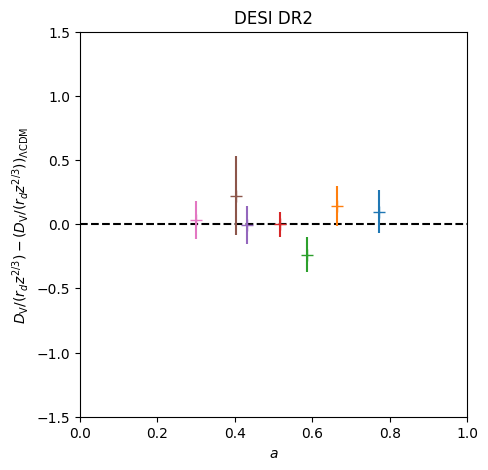

In [14]:
%matplotlib inline 
# ── Plot ──────────────────────────────────────────────────────────────────────

# C0-C6 in standard order: BGS, LRG, LRG, LRG+ELG, ELG, QSO, Ly-α
labels = ["BGS", "LRG", "LRG", "LRG+ELG", "ELG", "QSO", r"Ly-$\alpha$"]
colors = [f"C{i}" for i in range(7)]
a_vals = 1 / (1 + zv_all)

fig, ax = plt.subplots(figsize=(5, 5))
ax.axhline(0, color='k', linestyle='--')

for a, res, err, label, color in zip(a_vals, residuals, ratio_std, labels, colors):
    ax.errorbar(a, res, yerr=err, marker='+', markersize=8, linewidth=1.5,
                color=color, label=label, capsize=0)

ax.set(
    xlabel=r'$a$',
    ylabel=r'$D_\mathrm{V}/(r_d z^{2/3}) - (D_\mathrm{V}/(r_d z^{2/3}))_{\Lambda\mathrm{CDM}}$',
    xlim=(0, 1),
    ylim=(-1.5, 1.5),
    title='DESI DR2',
)

# ── Your theory ───────────────────────────────────────────────────────────────
# Replace my_theory() with your own function returning (z_array, H_array).
h = 0.7
H0 = 100*h
OmL = (1-omega_m-omega_r(h))
stigma = 1
mups2 = 4/3
cpr = 0.9991
ombh2=0.02242
omch2=0.11933
omega_m = (ombh2+omch2)/h**2

z_arr, H_arr,P_DE, rho_DE, asol = rhopsol(cpr, omega_m, h, OmL, stigma, mups2)
h_interp = interp1d(z_arr, H_arr / H_arr[0], kind='cubic')
pars = camb.CAMBparams()
pars.set_cosmology(H0=H0, ombh2=ombh2, omch2=omch2, omk=0)
pars.set_dark_energy_rho_p_a(a_p=asol, a_rho=asol,p=P_DE, rho=rho_DE)
pars.set_for_lmax(2500, lens_potential_accuracy=0)
pars.InitPower.set_params(As=2.1e-9, ns=0.965, r=0)

results = camb.get_background(pars)
rd_theory      = results.get_derived_params()['rdrag']  # Mpc
h0rd_theory    = H0 * rd_theory                        
print(h0rd_theory)

def theory_dv_over_rdz23(z):
    integral, _ = quad(lambda zp: 1/float(h_interp(zp)), 0, z)
    dm = c_kms / h0rd_theory * integral
    dh = c_kms / h0rd_theory / float(h_interp(z))
    return (z * dm**2 * dh)**(1/3) / z**(2/3)

a_plot = np.linspace(0.01, 0.99, 2000)
z_plot = 1/a_plot - 1
theory_res = np.array([theory_dv_over_rdz23(z) - lcdm_dv_over_rdz23(z) for z in z_plot])
ax.plot(a_plot, theory_res, color='k', linewidth=1.5, label='My theory')

# ─────────────────────────────────────────────────────────────────────────────


ax.legend(fontsize='small')
fig.tight_layout()


In [ ]:
plt.plot(z_arr,h_interp(z_arr))
plt.plot(z_arr, E(z_arr, omega_m))
plt.plot(z_arr, H(1/(1+z_arr), omega_m, h)/(h*100), "--")

In [ ]:
def theory_ratio(z):
    integral, _ = quad(lambda zp: 1/float(h_interp(zp)), 0, z)
    return float(h_interp(z)) * integral / z


# ── 5. PLOT ───────────────────────────────────────────────────────────────────

fig, ax = plt.subplots(figsize=(5, 5))
ax.axhline(0, color='k', linestyle='--')

for a, res, err, label, color in zip(a_vals, residuals, ratio_std, labels, colors):
    ax.errorbar(a, res, yerr=err, marker='+', markersize=8, linewidth=1.5,
                color=color, label=label, capsize=0)

a_plot = np.linspace(0.01, 0.99, 200)
z_plot = 1 / a_plot - 1
theory_res = np.array([theory_ratio(z) - lcdm_ratio(z) for z in z_plot])
ax.plot(a_plot, theory_res, color='k', linewidth=1.5, label='My theory')

ax.set(
    xlabel=r'$a$',
    ylabel=r'$D_\mathrm{M}/(zD_H) - (D_\mathrm{M}/(zD_H))_{\Lambda\mathrm{CDM}}$',
    xlim=(0, 1),
    ylim=(-0.25, 0.25),
    title='DESI DR2',
)
ax.legend(fontsize='small')
fig.tight_layout()

In [ ]:
print(f"ΛCDM best fit H0rd: {h0rd_bf:.2f}")     
print(f"Theory H0rd:        {h0rd_theory:.2f}") 